# Audio Computing - Lab 3: Reverberation and 3D Audio

In this lab we will get some experience in simulating rooms and 3D audio. For reverb, we will design some simple reverbs using small filters and then work towards a more principled room simulator. You can use whichever sound you like for the following examples, usually a sound with sharp onsets is good for such experiments. One good example is the drum loop [ https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1 ]

In [1]:
# Load a remote WAVE file given its URL, and return the sample rate and waveform
def wavreadurl( url):
    import urllib.request, io, scipy.io.wavfile
    f = urllib.request.urlopen( urllib.request.Request( url))
    sr,s = scipy.io.wavfile.read( io.BytesIO( f.read()))
    return sr, s.astype( 'float32')/32768

# Make a sound player function that plays array "x" with a sample rate "rate", and labels it with "label"
def sound( x, rate=8000, label=''):
    from IPython.display import display, Audio, HTML
    display( HTML( 
    '<style> table, th, td {border: 0px; }</style> <table><tr><td>' + label + 
    '</td><td>' + Audio( x, rate=rate)._repr_html_()[3:] + '</td></tr></table>'
    ))

# Import graphics
from matplotlib.pylab import xlabel, ylabel, title, stem, subplot, pcolormesh, plot, semilogy, legend

sr,s = wavreadurl( 'https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
sound( s, sr)

,Your browser does not support the audio element.


## Part 1. Designing simple reverb using filters

The simplest forms of reverbs can be designed using simple delays, comb and allpass filters. We will design one of each to get started.

a) A room with a single wall. For this reverb we will assume that we have a room that only has one reflective wall as shown below. Design a filter that simulates what the microphone will record. Figure out the right filter in the case where $d_i = [0.2, 1]$ meters, and in the case where $d_i = [2, 10]$ meters. Let me know what the differences between these sounds are. To keep things simple, round the delays to an integer number and make up an approximate gain loss due to propagation and the wall bounce. Make sure to plot the resulting filters and their frequency responses, as well as to render the test sound with these two reverbs applied on it.

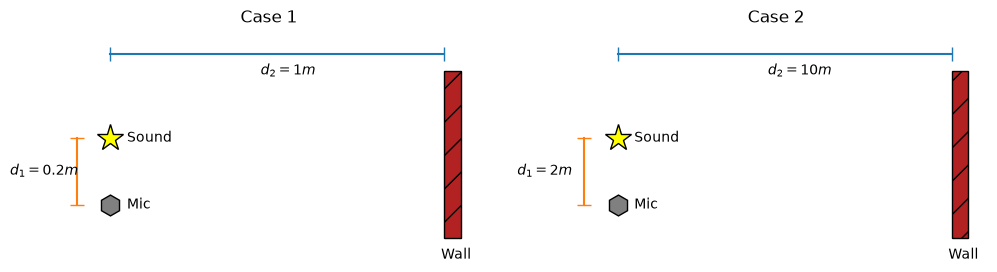

In [2]:
# Run this cell to see a representation of the situation to model
from matplotlib.pylab import gca, gcf, figure
from matplotlib.patches import Rectangle

figure( figsize=(12,3), facecolor='w')
gcf().add_subplot( 1, 2, 1, title='Case 1', frameon=False, xticks=[], yticks=[])
gca().plot( 0, 0, 'h', color='grey', markeredgecolor='k', markersize=15)
gca().plot( 0, .2, '*', color='yellow', markeredgecolor='k', markersize=20)
gca().plot( [0,1], [.45,.45], marker='|', markersize=10)
gca().plot( [-.1,-.1], [0,.2], marker='_', markersize=10)
gca().add_patch( Rectangle( (1,-.1), .05, .5, facecolor='firebrick', edgecolor='k', hatch='/'))
[gca().text(x+.05,y,t,va='center',ha='left') 
    for x,y,t in zip( [0,0,-.35,.4,.94], [0,.2,.1,.4,-.15], ['Mic','Sound','$d_1=0.2m$', '$d_2=1m$', 'Wall'])]
gca().axis( 'equal')

gcf().add_subplot( 1, 2, 2, title='Case 2', frameon=False, xticks=[], yticks=[])
gca().plot( 0, 0, 'h', color='grey', markeredgecolor='k', markersize=15)
gca().plot( 0, .2, '*', color='yellow', markeredgecolor='k', markersize=20)
gca().plot( [0,1], [.45,.45], marker='|', markersize=10)
gca().plot( [-.1,-.1], [0,.2], marker='_', markersize=10)
gca().add_patch( Rectangle( (1,-.1), .05, .5, facecolor='firebrick', edgecolor='k', hatch='/'))
[gca().text(x+.05,y,t,va='center',ha='left') 
    for x,y,t in zip( [0,0,-.35,.4,.94], [0,.2,.1,.4,-.15], ['Mic','Sound','$d_1=2m$', '$d_2=10m$', 'Wall'])]
gca().axis( 'equal');

In [3]:
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt


def impulseResponse(b, a, N):
    x = np.zeros(N)
    x[0] = 1
    return signal.lfilter(b, a, x)


def filterSpectrum(b, a, fs, N=2**15):
    return signal.freqz(b, a, worN=N, fs=fs)


def plotIR(h, fs, title, style="stem"):
    h = h[:, None] if h.ndim == 1 else h
    t = np.arange(len(h)) / fs
    labels = ["Left", "Right"] if h.shape[1] == 2 else [None]
    plt.figure(figsize=(10, 3.5))
    for k, label in enumerate(labels):
        if style == "stem":
            plt.vlines(t, 0, h[:, k], color=f"C{k}", lw=1)
            plt.plot(t, h[:, k], "o", ms=3, color=f"C{k}", label=label)
        else:
            plt.plot(t, h[:, k], "-" if k == 0 else "--", lw=1, color=f"C{k}", label=label)
    if labels[0]:
        plt.legend()
    plt.title(title)
    plt.xlabel("Time [s]")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()


def plotSpectrum(f, H, title, minDb=None, maxDb=None, maxFreq=None, phase=True):
    rows = 2 if phase else 1
    fig, ax = plt.subplots(rows, 1, sharex=True, figsize=(10, 3 * rows), squeeze=False)
    ax = ax[:, 0]
    ax[0].plot(f, 20 * np.log10(np.maximum(np.abs(H), 1e-12)))
    ax[0].set_ylabel("Magnitude [dB]")
    ax[0].set_ylim(minDb, maxDb)
    ax[0].grid(True)
    if phase:
        ax[1].plot(f, np.angle(H))
        ax[1].set_ylabel("Phase [rad]")
        ax[1].grid(True)
    ax[-1].set_xlabel("Frequency [Hz]")
    ax[-1].set_xlim(0, maxFreq)
    fig.suptitle(title)
    plt.show()

Original sound,Your browser does not support the audio element.


d = [0.2, 1] m: reflection 5.3 ms after the direct sound, -21.6 dB


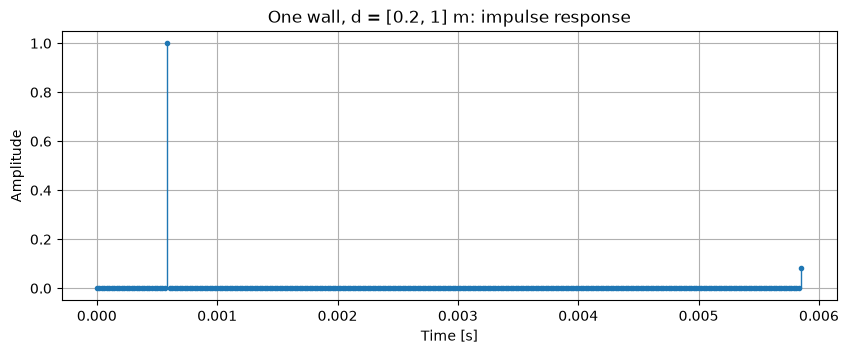

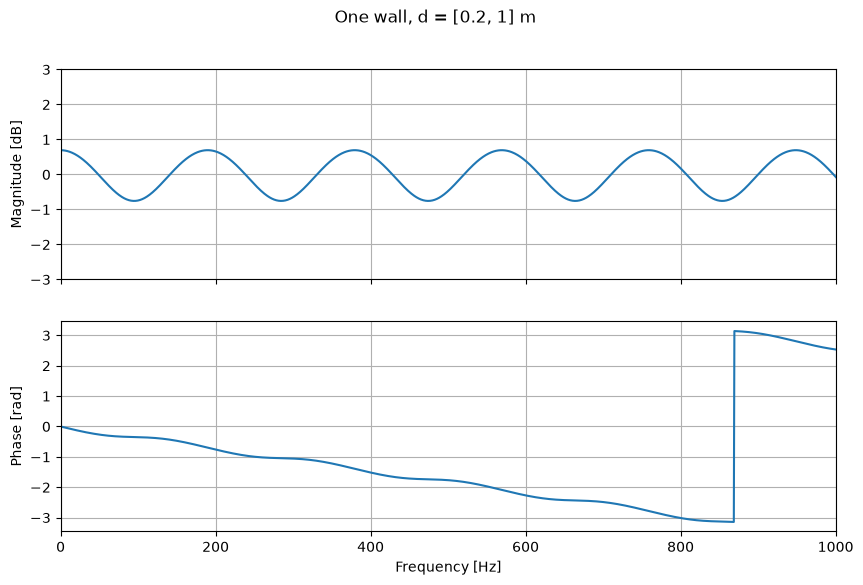

"One wall, d = [0.2, 1] m",Your browser does not support the audio element.


d = [2, 10] m: reflection 52.7 ms after the direct sound, -21.6 dB


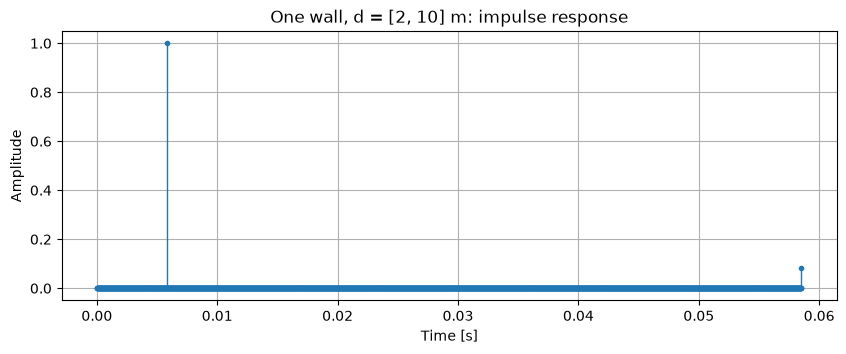

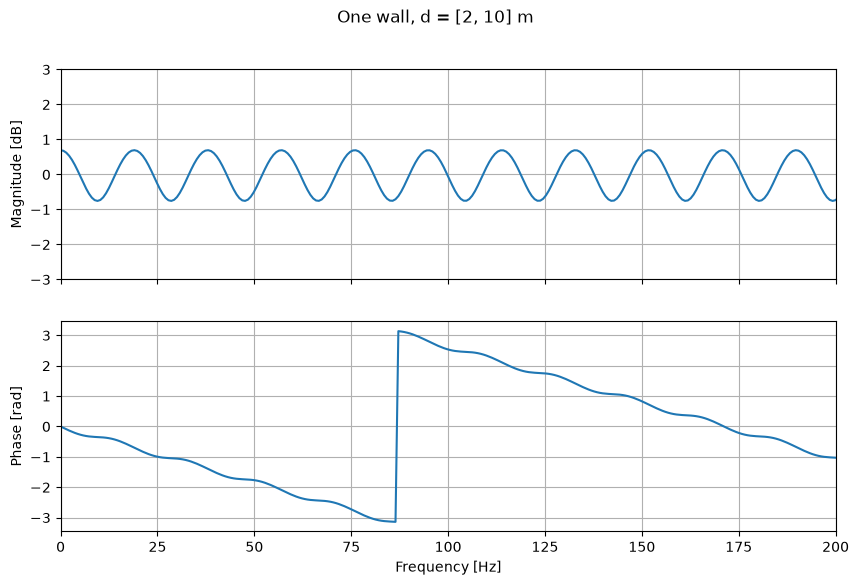

"One wall, d = [2, 10] m",Your browser does not support the audio element.


In [4]:
sr, s = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
sound(s, sr, "Original sound")


def speedOfSound(temp=20.0):
    return 331.3 + 0.606 * temp


def oneWallIR(fs, d1, d2, alpha=0.3, temp=20.0):
    c = speedOfSound(temp)
    dRefl = np.sqrt((2 * d2) ** 2 + d1 ** 2) #spiegelquelle hinter der wand
    n1, n2 = int(round(d1 / c * fs)), int(round(dRefl / c * fs))
    h = np.zeros(n2 + 1)
    h[n1] = 1.0
    h[n2] = d1 / dRefl * np.sqrt(1 - alpha) #1/r-abfall + absorption der wand
    return h


for d1, d2 in [(0.2, 1), (2, 10)]:
    h = oneWallIR(sr, d1, d2)
    n = np.nonzero(h)[0]
    print(f"d = [{d1}, {d2}] m: reflection {(n[1] - n[0]) / sr * 1000:.1f} ms after the direct sound, {20 * np.log10(h[n[1]]):.1f} dB")
    plotIR(h, sr, f"One wall, d = [{d1}, {d2}] m: impulse response")
    f, H = filterSpectrum(h, 1, sr)
    plotSpectrum(f, H, f"One wall, d = [{d1}, {d2}] m", minDb=-3, maxDb=3, maxFreq=1000 if d1 < 1 else 200)
    sound(np.convolve(s, h), sr, f"One wall, d = [{d1}, {d2}] m")

#die reflexion liegt in beiden fällen ca. 22 db unter dem direktschall (1/r über einen ca. 10x längeren weg)
#nah: 5.3 ms später -> kammfilter-rippel von ±0.7 db alle ca. 190 hz, eher eine leichte färbung als ein echo
#fern: 52.7 ms später -> über der echoschwelle (ca. 50 ms), also ein eigenes leises echo

b) Now we will use a room geometry as shown below. Design the proper filter again, for $d = 1$ meters and then for $d = 10$ meters. Comment on the audible differences between these two settings.

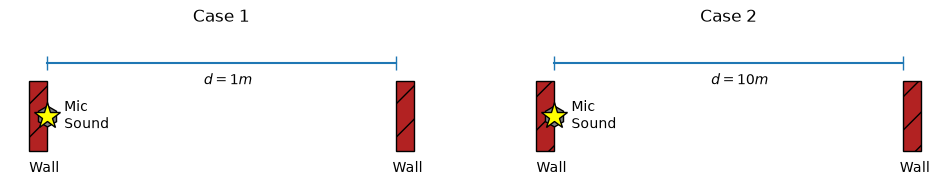

In [5]:
# Run this cell to see a representation of the situation to model
figure( figsize=(12,2), facecolor='w')
gcf().add_subplot( 1, 2, 1, title='Case 1', frameon=False, xticks=[], yticks=[])
gca().plot( 0, 0, 'h', color='grey', markeredgecolor='k', markersize=15)
gca().plot( 0, 0, '*', color='yellow', markeredgecolor='k', markersize=20)
gca().plot( [0,1], [.15,.15], marker='|', markersize=10)
gca().add_patch( Rectangle( (1,-.1), .05, .2, facecolor='firebrick', edgecolor='k', hatch='/'))
gca().add_patch( Rectangle( (0,-.1), -.05, .2, facecolor='firebrick', edgecolor='k', hatch='/'))
[gca().text(x+.05,y,t,va='center',ha='left') 
    for x,y,t in zip( [0,.4,.94,-.1], [0,.1,-.15,-.15], ['Mic\nSound','$d=1m$','Wall','Wall'])]
gca().axis( 'equal')

gcf().add_subplot( 1, 2, 2, title='Case 2', frameon=False, xticks=[], yticks=[])
gca().plot( 0, 0, 'h', color='grey', markeredgecolor='k', markersize=15)
gca().plot( 0, 0, '*', color='yellow', markeredgecolor='k', markersize=20)
gca().plot( [0,1], [.15,.15], marker='|', markersize=10)
gca().add_patch( Rectangle( (1,-.1), .05, .2, facecolor='firebrick', edgecolor='k', hatch='/'))
gca().add_patch( Rectangle( (0,-.1), -.05, .2, facecolor='firebrick', edgecolor='k', hatch='/'))
[gca().text(x+.05,y,t,va='center',ha='left') 
    for x,y,t in zip( [0,.4,.94,-.1], [0,.1,-.15,-.15], ['Mic\nSound','$d=10m$','Wall','Wall'])]
gca().axis( 'equal');

Original sound,Your browser does not support the audio element.


d = 1 m: N = 280 samples (5.8 ms), g = 0.951


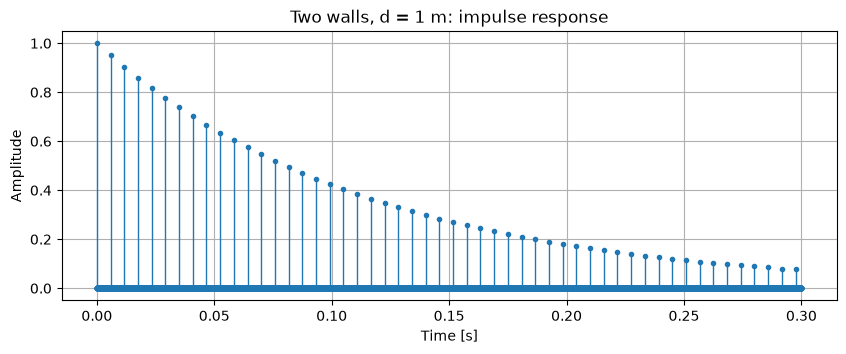

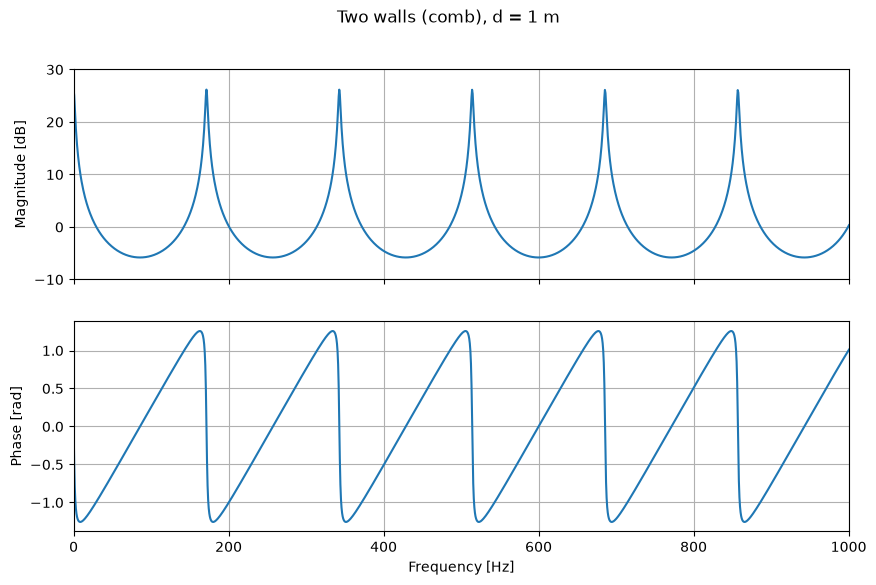

"Two walls, d = 1 m",Your browser does not support the audio element.


d = 10 m: N = 2795 samples (58.2 ms), g = 0.605


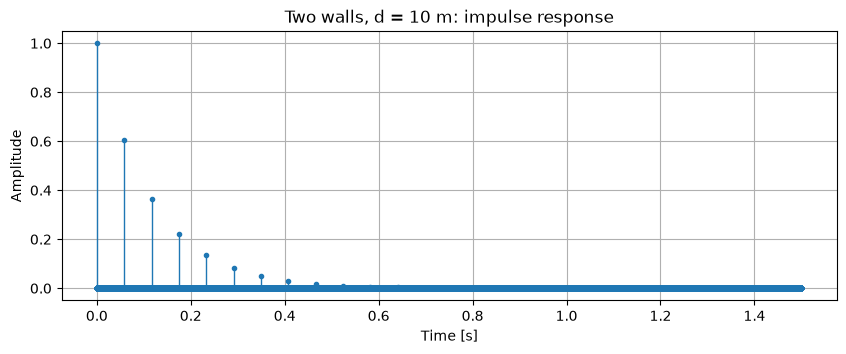

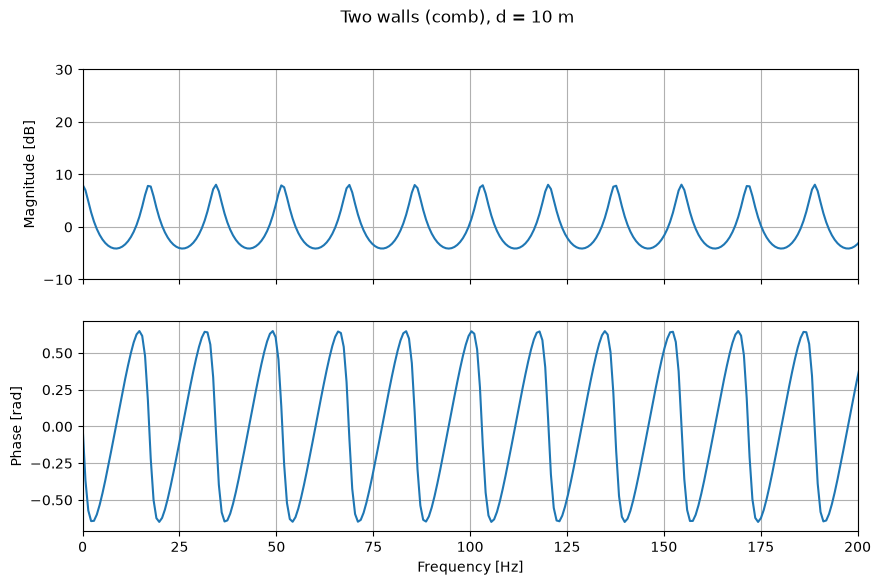

"Two walls, d = 10 m",Your browser does not support the audio element.


In [6]:
sr, s = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
sound(s, sr, "Original sound")


def gainForRT60(N, fs, T60):
    return 10 ** (-3 * N / (fs * T60)) #-60 db nach t60 sekunden


def combFilter(N, g):
    b = np.zeros(N + 1)
    a = np.zeros(N + 1)
    b[0] = 1
    a[0] = 1
    a[N] = -g
    return b, a


def roundTrip(fs, d, temp=20.0):
    return int(round(2 * d / speedOfSound(temp) * fs))


for d, irLength in [(1, 0.3), (10, 1.5)]:
    N = roundTrip(sr, d)
    g = gainForRT60(N, sr, 0.8)
    b, a = combFilter(N, g)
    print(f"d = {d} m: N = {N} samples ({N / sr * 1000:.1f} ms), g = {g:.3f}")
    plotIR(impulseResponse(b, a, int(irLength * sr)), sr, f"Two walls, d = {d} m: impulse response")
    f, H = filterSpectrum(b, a, sr)
    plotSpectrum(f, H, f"Two walls (comb), d = {d} m", minDb=-10, maxDb=30, maxFreq=1000 if d < 5 else 200)
    sound(signal.lfilter(b, a, s), sr, f"Two walls, d = {d} m")

#beide mit derselben rt60 (0.8 s), daher hängt g von der verz. ab: 0.95 bei 1 m, 0.61 bei 10 m
#1 m: spitzen alle 172 hz mit +26 db -> starke resonanz, als tonhöhe hörbar
#10 m: spitzen alle 17 hz mit +8 db -> weniger färbung, aber getrennte echos alle 58 ms (flatterecho)

c) Since for small values of $d$ the output above gets its spectrum altered, we will use an allpass filter to make a more natural sounding echo pattern. Use the formulation shown in the lecture slides and compare that filter’s frequency response with the response from the filter in the section b) above.

Original sound,Your browser does not support the audio element.


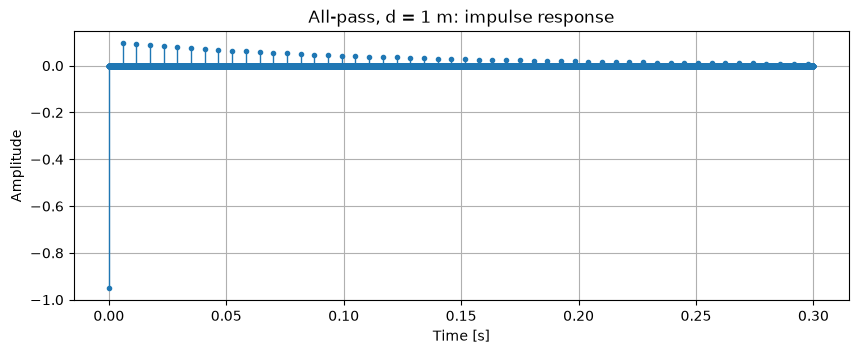

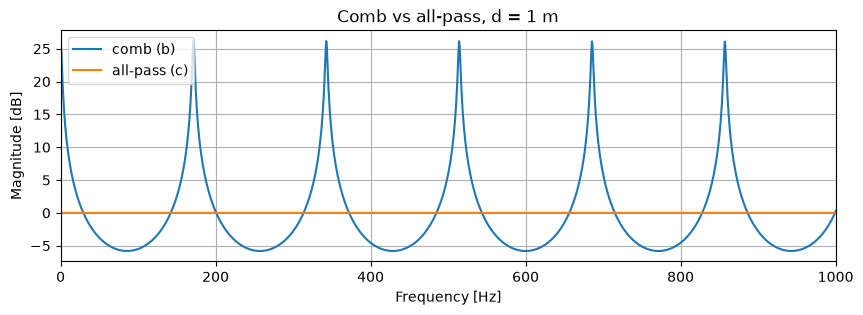

"All-pass, d = 1 m",Your browser does not support the audio element.


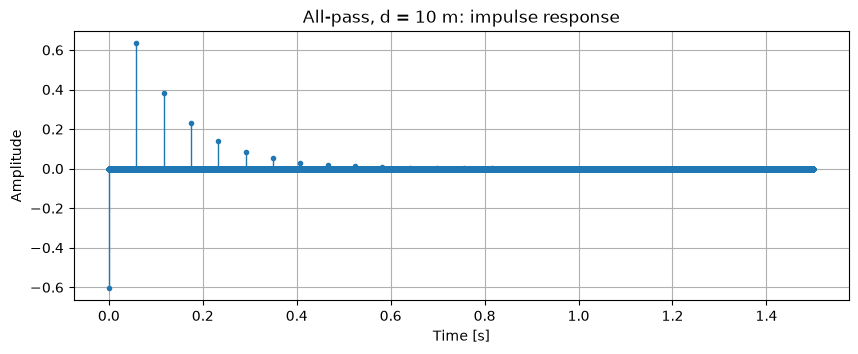

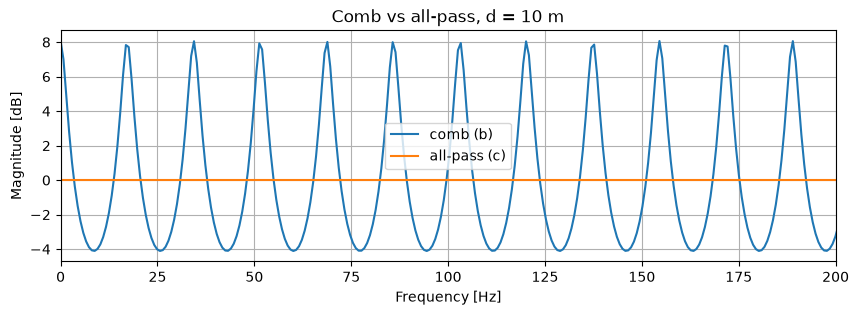

"All-pass, d = 10 m",Your browser does not support the audio element.


In [7]:
sr, s = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
sound(s, sr, "Original sound")


def allpassFilter(N, g):
    b = np.zeros(N + 1)
    a = np.zeros(N + 1)
    b[0] = -g
    b[N] = 1
    a[0] = 1
    a[N] = -g
    return b, a


for d, irLength in [(1, 0.3), (10, 1.5)]:
    N = roundTrip(sr, d)
    g = gainForRT60(N, sr, 0.8)
    b, a = allpassFilter(N, g)
    plotIR(impulseResponse(b, a, int(irLength * sr)), sr, f"All-pass, d = {d} m: impulse response")
    f, Hap = filterSpectrum(b, a, sr)
    _, Hcomb = filterSpectrum(*combFilter(N, g), sr)
    plt.figure(figsize=(10, 3))
    plt.plot(f, 20 * np.log10(np.abs(Hcomb)), label="comb (b)")
    plt.plot(f, 20 * np.log10(np.abs(Hap)), label="all-pass (c)")
    plt.xlim(0, 1000 if d < 5 else 200)
    plt.title(f"Comb vs all-pass, d = {d} m")
    plt.xlabel("Frequency [Hz]")
    plt.ylabel("Magnitude [dB]")
    plt.legend()
    plt.grid(True)
    plt.show()
    sound(signal.lfilter(b, a, s), sr, f"All-pass, d = {d} m")

#gleiche verz. u. gleiches abklingen wie der kamm, aber der betragsgang ist flach (0 db): die +26-db-spitzen sind weg
#das echomuster in der zeit bleibt gleich, daher sind die echos bei 10 m weiterhin getrennt

## Part 2. Schroeder reverberators

Now we will combine multiple filters to make a more serious sounding reverb. Implement the structure shown in slide 26 of the reverb lecture (the slide is titled "*Wetness of reverb*").

Try to find the necessary parameters for the above structure that makes it sound as good as possible (not too busy, not too subtle). Hint: There is no right answer! Try a few things, see what sounds best and explain why you used the parameters you decided to use. As you come across some bad sounding cases, describe what the problem was. As always show us nice plots that show what you've done, and make sure you render the sound outputs too.

Dry,Your browser does not support the audio element.


Small room: measured RT60 = 0.48 s


Small room,Your browser does not support the audio element.


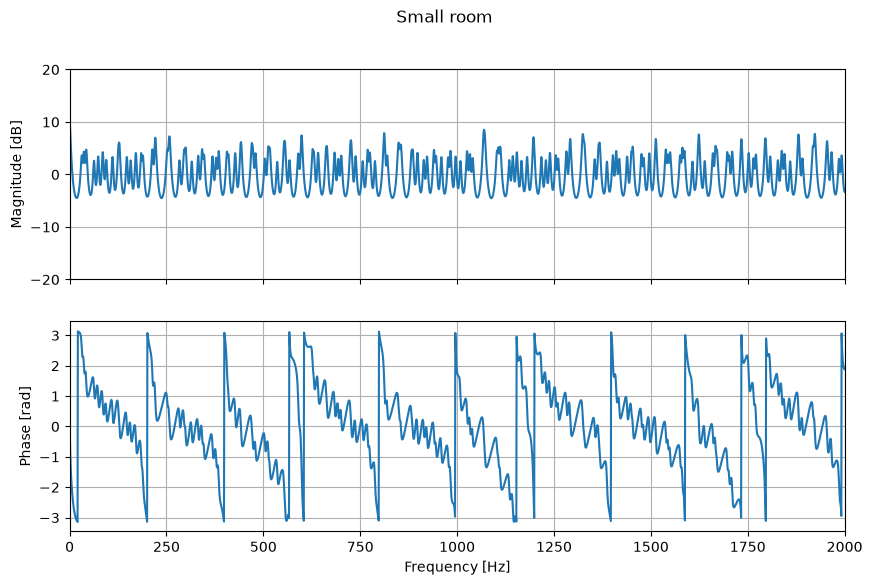

Small room, harmonic comb delays: measured RT60 = 0.48 s


"Small room, harmonic comb delays",Your browser does not support the audio element.


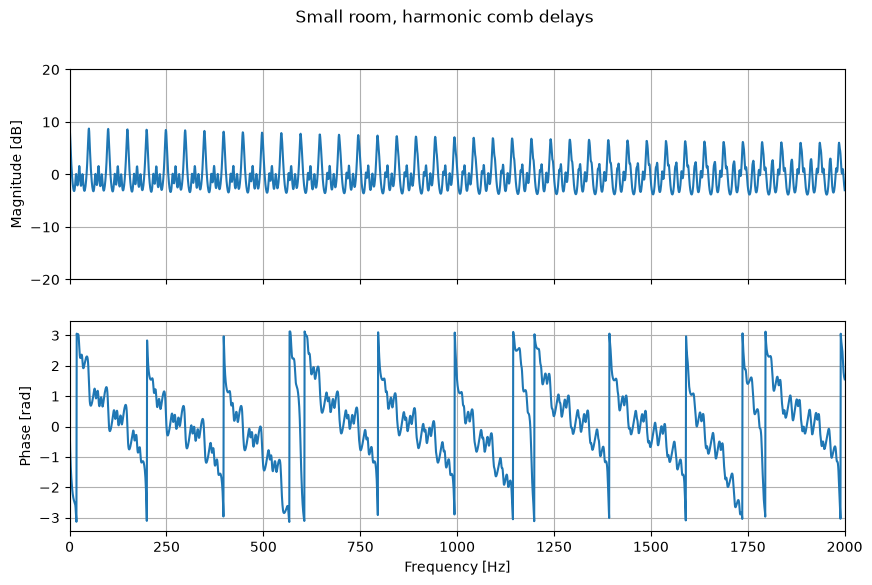

Small room, all-pass delays too long: measured RT60 = 1.77 s


"Small room, all-pass delays too long",Your browser does not support the audio element.


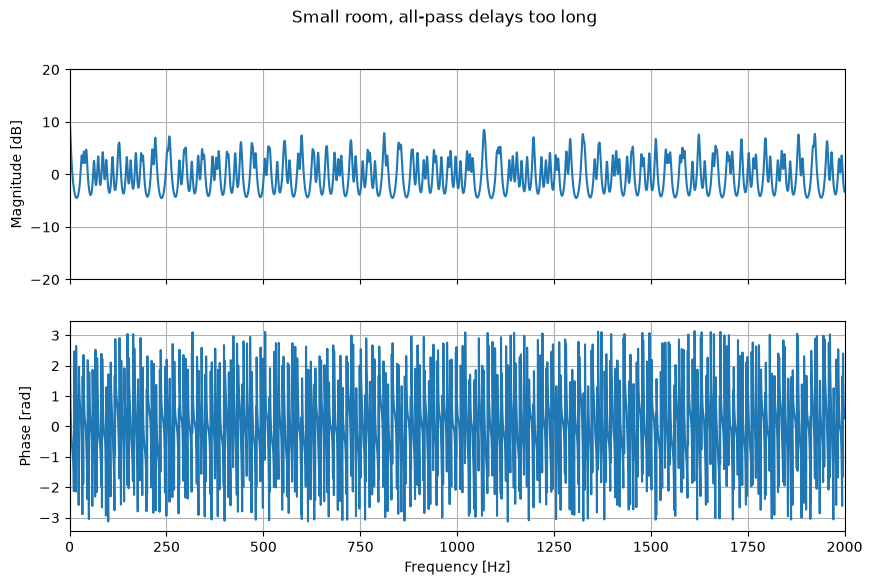

Large hall: measured RT60 = 2.00 s


Large hall,Your browser does not support the audio element.


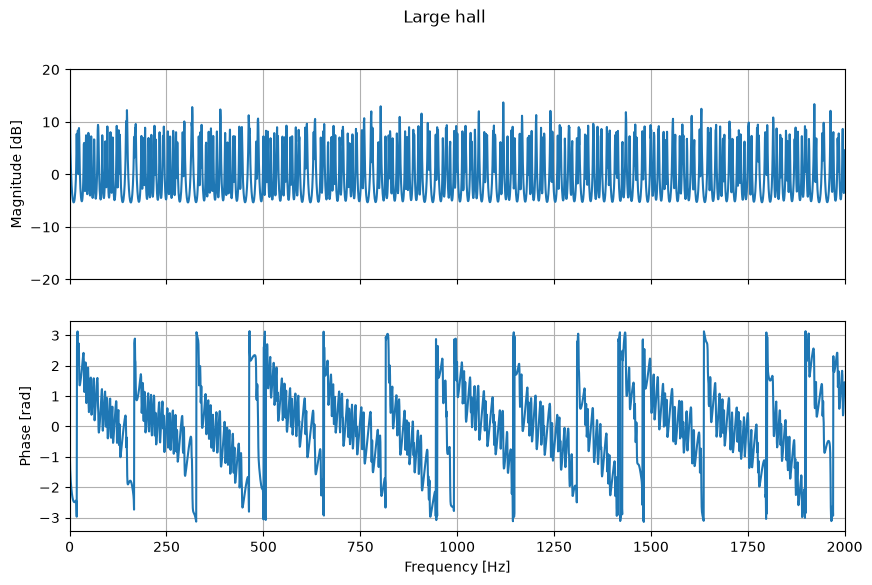

Large hall, too wet: measured RT60 = 2.00 s


"Large hall, too wet",Your browser does not support the audio element.


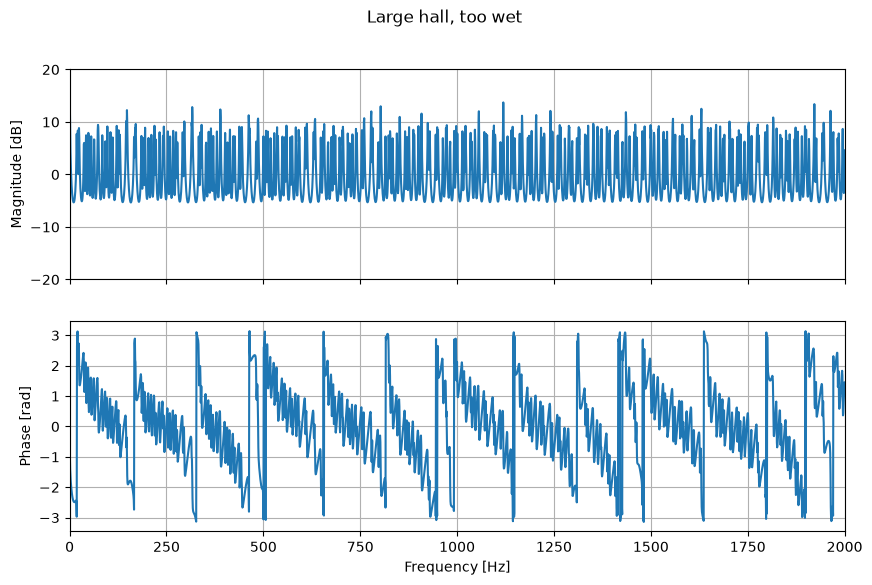

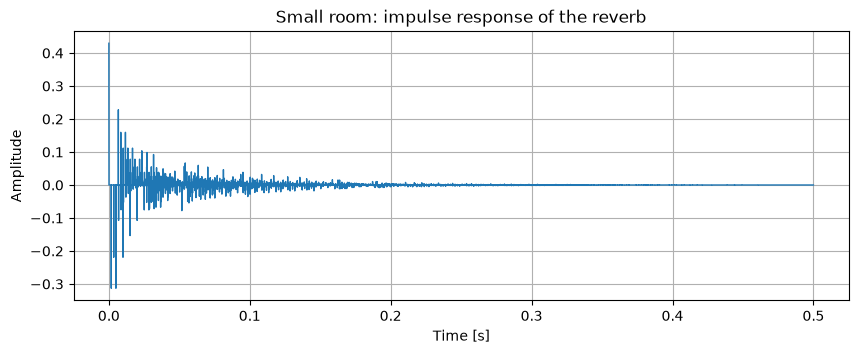

In [8]:
sr, s = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
sound(s, sr, "Dry")


def isPrime(n):
    return n > 1 and all(n % k for k in range(2, int(np.sqrt(n)) + 1))


def primeDelay(ms, fs):
    N = int(round(ms * 1e-3 * fs))
    while not isPrime(N):
        N += 1
    return N


def schroederReverb(x, fs, combMs, allpassMs, T60=1.0, gAp=0.7, wet=0.3):
    y = np.zeros(len(x))
    H = 0
    for ms in combMs:
        N = primeDelay(ms, fs)
        b, a = combFilter(N, gainForRT60(N, fs, T60))
        y += signal.lfilter(b, a, x) / len(combMs)
        f, Hc = filterSpectrum(b, a, fs)
        H = H + Hc / len(combMs)
    for ms in allpassMs:
        b, a = allpassFilter(primeDelay(ms, fs), gAp)
        y = signal.lfilter(b, a, y)
        H = H * filterSpectrum(b, a, fs)[1]
    y *= np.std(x) / np.std(y)
    return (1 - wet) * x + wet * y, f, H


def estimateRT60(h, fs):
    e = np.cumsum(h[::-1] ** 2)[::-1]
    e = 10 * np.log10(e / e[0] + 1e-30)
    return 3 * (np.argmax(e < -25) - np.argmax(e < -5)) / fs #t20, auf 60 db hochgerechnet


settings = [
    ("Small room", [23.3, 27.1, 31.7], [5.0, 1.7], 0.5, 0.25),
    ("Small room, harmonic comb delays", [20.0, 40.0, 60.0], [5.0, 1.7], 0.5, 0.25),
    ("Small room, all-pass delays too long", [23.3, 27.1, 31.7], [60.0, 85.0], 0.5, 0.25),
    ("Large hall", [41.1, 47.3, 53.9], [6.0, 2.1], 2.0, 0.35),
    ("Large hall, too wet", [41.1, 47.3, 53.9], [6.0, 2.1], 2.0, 0.8),
]

impulse = np.zeros(4 * sr)
impulse[0] = 1
for name, combMs, allpassMs, T60, wet in settings:
    y, f, H = schroederReverb(s, sr, combMs, allpassMs, T60, wet=wet)
    hWet, _, _ = schroederReverb(impulse, sr, combMs, allpassMs, T60, wet=1.0)
    print(f"{name}: measured RT60 = {estimateRT60(hWet, sr):.2f} s")
    sound(y, sr, name)
    plotSpectrum(f, H, name, minDb=-20, maxDb=20, maxFreq=2000)

hWet, _, _ = schroederReverb(impulse[:int(0.5 * sr)], sr, [23.3, 27.1, 31.7], [5.0, 1.7], 0.5, wet=1.0)
plotIR(hWet, sr, "Small room: impulse response of the reverb", style="line")

#verz. auf primzahlen von samples aufgerundet, damit die kamm-echos selten zusammenfallen
#kamm-gains aus der ziel-rt60, die gemessene rt60 passt (0.48 s für 0.5 s, 2.00 s für 2.0 s)
#harmonische verz. (20/40/60 ms): die kammspitzen liegen übereinander -> regelmäßige resonanzen im plot
#ap-verz. zu lang (60/85 ms): die allpässe klingen selbst nach, rt60 springt von 0.48 auf 1.77 s
#zu nass (0.8): die drums sind zu 80 % hall u. verlieren ihren anschlag, 0.25-0.35 lässt sie klar

## Part 3. Applying a real room response

To apply a more realistic filter we need to use a real room response. Download the St. Andrew’s church room impulse response (Stereo) from:

[ https://www.space-net.hosted.york.ac.uk/node/53/index.html ]

Make sure that the sound you will convolve with it will be at the same sampling rate. This impulse response captures that church’s RIR using two channels. To synthesize a sound in that room you need to convolve it with the impulse response. If your test sound is a single-channel recording, you can simply convolve it with each of the two impulse responses and then use the resulting outputs as the left and right channel. You will notice that using the ```scipy.signal.lfilter``` command for this operation can take very long to compute. For faster convolutions we need to perform this filtering in the frequency domain (using the fast convolution algorithm that we mentioned in the filtering lecture). The function ```numpy.convolve``` automatically does that (if you use an up to date version), otherwise you can directly use ```scipy.signal.fftconvolve```.  Verify that the resulting output sounds like it has been placed inside a church.


St Andrew's church: RT60 L/R = 1.33 / 1.34 s


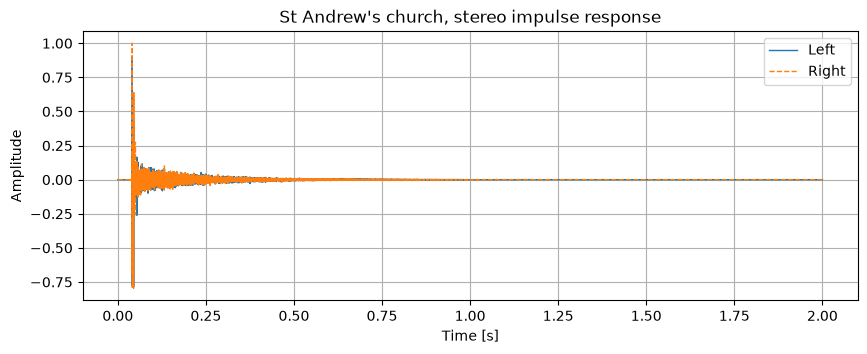

Drums in St Andrew's church,Your browser does not support the audio element.


In [9]:
from scipy.io import wavfile

sr, s = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')


def convolveIR(x, h):
    if h.ndim == 1:
        return signal.fftconvolve(x, h)
    return np.array([signal.fftconvolve(x, h[:, k]) for k in range(h.shape[1])])


fsIR, h = wavfile.read("roomresponse_standrewschurch_48k.wav")
assert fsIR == sr
h = h.astype(float) / np.max(np.abs(h))
print(f"St Andrew's church: RT60 L/R = {estimateRT60(h[:, 0], fsIR):.2f} / {estimateRT60(h[:, 1], fsIR):.2f} s")
plotIR(h, fsIR, "St Andrew's church, stereo impulse response", style="line")
sound(convolveIR(s, h), sr, "Drums in St Andrew's church")

#kirche: rt60 ca. 1.33 s auf beiden kanälen, ca. 4x das badezimmer

## Part 4. Measuring a room response.

#### This is for grad student credit, or extra credit for undergrads

Measuring a room response is crucial when trying to emulate a real room. In this exercise we will make a room response measurement. We will use the technique shown in the lecture slides.

a) Generate a chirp to use as our room excitation signal.

b) Go to a (preferably quiet) room that you want to measure, play the chirp from a speaker and record the outcome (the easiest way to do that is to save this sequence as a wave file and play it while you record a new sound file).

c) Now you will need to perform the actual deconvolution. Take $x[t]$ and $y[t]$, compute their DFTs to get $X[ω]$ and $Y[ω]$, and estimate $H[ω]$ (remember to zero pad the inputs since the output of the convolution will be about twice as long as the inputs). Take the inverse DFT of $H$ to get the time domain representation of the room impulse response. Does it look like one?

d) Convolve the resulting response with the test sound above (make sure you use the same sample rates). Does it sound reverberated? This won’t be perfect. What sounds “wrong” with it? Can you speculate why?

In [10]:
from scipy.io import wavfile
import warnings
from scipy.io.wavfile import WavFileWarning
from scipy.signal.windows import tukey

warnings.filterwarnings("ignore", category=WavFileWarning)

sr, s = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
fs = sr
T = 5.0 #länger = mehr energie, besseres snr
f0 = 40.0 #handy-lsp. geben so tief eh fast nichts wieder
f1 = 20000.0
A = 0.8 #reserve gegen clipping
fadeTime = 0.05 #gegen klicks

assert f1 < fs / 2 #sonst aliasing

n = np.arange(int(T * fs))
#exponentiell: gleich viel zeit pro oktave
fInst = f0 * (f1 / f0) ** (n / (len(n) - 1))
#phase = integral der freq.
phase = 2 * np.pi * np.cumsum(fInst) / fs
x = A * np.sin(phase)

x *= tukey(len(x), alpha=2 * fadeTime / T)

wavfile.write("chirp_exp_40hz-20khz_5s.wav", fs, np.int16(x * 32767))
#aufbau: wohnheim-badezimmer, chirp auf einem pixel 8 abgespielt u. ca. 1.5 m entfernt mit einem zweiten pixel 8 aufgenommen (audio recorder app, wav, 48 khz, stereo)
#die qualität ist durch die handys begrenzt: kleiner lsp. (wenig bass) u. ein mic mit eigener verarbeitung (die app hat keinen raw-modus)
sound(x, fs, "Generated chirp")

Generated chirp,Your browser does not support the audio element.


Chirp recorded in my bathroom,Your browser does not support the audio element.


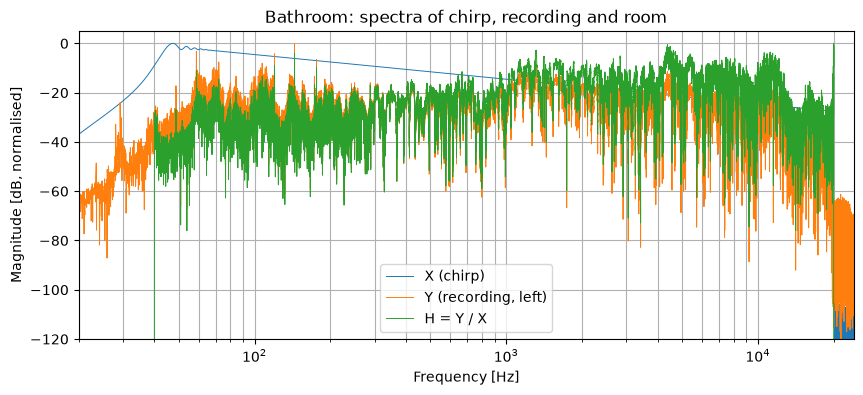

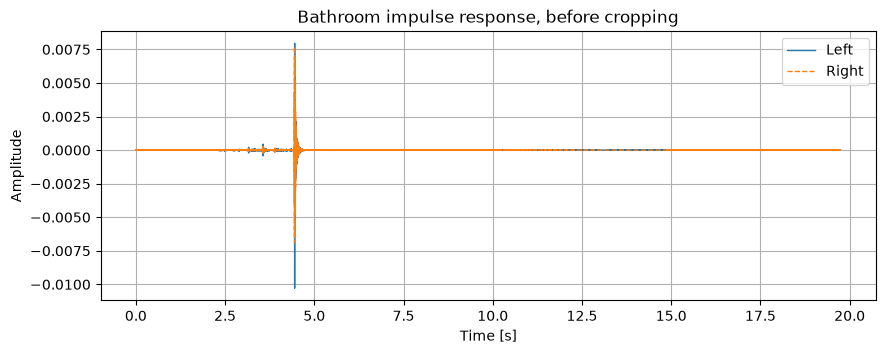

RT60 from the chirp IR: 0.34 s


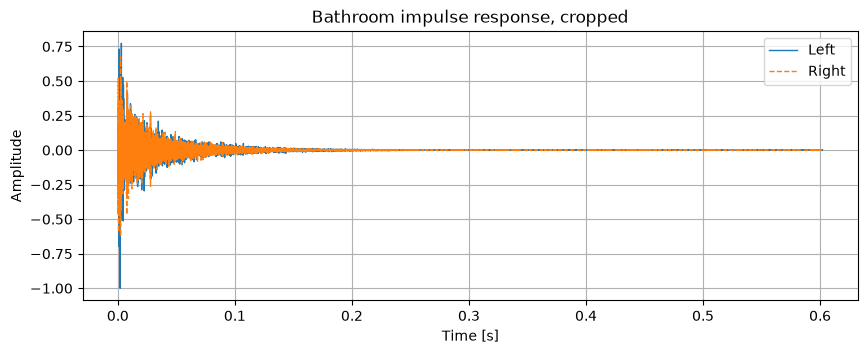

Bathroom impulse response,Your browser does not support the audio element.


Drums in my bathroom,Your browser does not support the audio element.


In [11]:
def wavreadFloat(filename):
    fs, x = wavfile.read(filename)
    if x.dtype.kind == "i":
        x = x / np.iinfo(x.dtype).max
    return fs, x.astype(float)


def deconvolve(x, y, fs, fLo=20.0, fHi=20000.0):
    N = len(x) + len(y) - 1 #zero-padding auf die volle faltungslänge
    X = np.fft.rfft(x, N)
    Y = np.fft.rfft(y, N, axis=0)
    f = np.fft.rfftfreq(N, 1 / fs)
    H = np.where(((f >= fLo) & (f <= fHi))[:, None], Y / (X[:, None] + 1e-8), 0) #nur der sweep-bereich
    return np.fft.irfft(H, N, axis=0)


def cropIR(h, fs, length=2.0):
    pk = np.argmax(np.max(np.abs(h), axis=1))
    h = h[max(pk - int(0.002 * fs), 0):pk + int(length * fs)]
    return h / np.max(np.abs(h))


def energyDecay(h):
    e = np.cumsum(h[::-1] ** 2)[::-1]
    return 10 * np.log10(e / e[0] + 1e-30)


fsX, xChirp = wavreadFloat("chirp_exp_40hz-20khz_5s.wav")
fsY, y = wavreadFloat("bathroom_chirp_recording.wav")
if y.ndim == 1:
    y = np.column_stack((y, y))
assert fsY == fsX
sound(y.T, fsY, "Chirp recorded in my bathroom")

N = len(xChirp) + len(y) - 1
f = np.fft.rfftfreq(N, 1 / fsX)
X, Y = np.fft.rfft(xChirp, N), np.fft.rfft(y[:, 0], N)
plt.figure(figsize=(10, 4))
Hroom = np.where((f >= f0) & (f <= f1), Y / (X + 1e-8), 0)
for spec, label in [(X, "X (chirp)"), (Y, "Y (recording, left)"), (Hroom, "H = Y / X")]:
    plt.semilogx(f[1:], 20 * np.log10(np.abs(spec[1:]) / np.abs(spec[1:]).max() + 1e-12), lw=0.7, label=label)
plt.xlim(20, fsX / 2)
plt.ylim(-120, 5)
plt.title("Bathroom: spectra of chirp, recording and room")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude [dB, normalised]")
plt.legend()
plt.grid(True, which="both")
plt.show()

hRaw = deconvolve(xChirp, y, fsX, f0, f1)
plotIR(hRaw, fsX, "Bathroom impulse response, before cropping", style="line")
h = cropIR(hRaw, fsX, 0.6)
print(f"RT60 from the chirp IR: {estimateRT60(h[:, 0], fsX):.2f} s")
plotIR(h, fsX, "Bathroom impulse response, cropped", style="line")
sound(h[:, 0], fsX, "Bathroom impulse response")
sound(convolveIR(s, h), sr, "Drums in my bathroom")
#gemessen: rt60 ca. 0.34 s, der hall erreicht nach ca. 0.3 s das grundrauschen (-68 db), daher werden 0.6 s ir behalten
#der handy-lsp. gibt unter ca. 250 hz fast nichts wieder (oben bis ca. 18 khz), daher ist die ir im bass dünn
#verzerrungen vom lsp. landen 0.5-1.5 s vor dem hauptpeak u. werden mit den 4.4 s stille abgeschnitten

RT60 from the balloon pop: 1.20 s


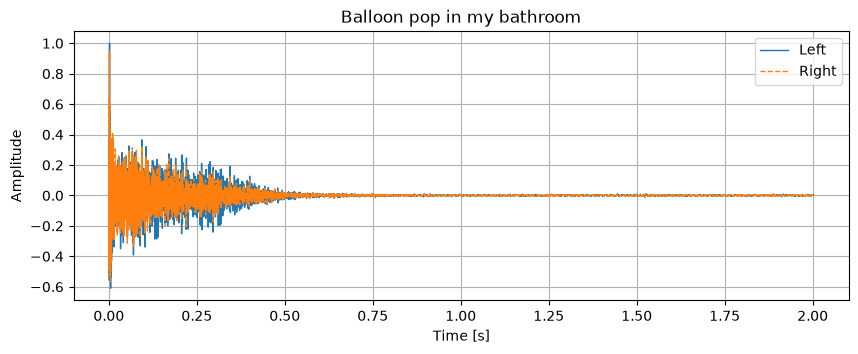

Balloon pop in my bathroom,Your browser does not support the audio element.


"Drums in my bathroom, balloon IR",Your browser does not support the audio element.


In [12]:
#ballonplatzer im badezimmer

fsB, b = wavreadFloat("bathroom_balloon_recording.wav")
if b.ndim == 1:
    b = np.column_stack((b, b))
assert fsB == sr
hB = cropIR(b, fsB, 2.0)
print(f"RT60 from the balloon pop: {estimateRT60(hB[:, 0], fsB):.2f} s")
plotIR(hB, fsB, "Balloon pop in my bathroom", style="line")
sound(hB.T, fsB, "Balloon pop in my bathroom")
sound(convolveIR(s, hB), sr, "Drums in my bathroom, balloon IR")
#ballon-rt60 1.2 s vs. 0.34 s vom chirp, aber bei 500 hz beide ca. 0.75 s
#-> vermutlich die automatische verstärkung vom handy, die nach dem lauten knall wieder aufdreht (die app hat keinen raw-modus)

During the Lab 3 session we collected measurements in Tull [https://www.dropbox.com/scl/fi/cwpfe5bjk0wud68a0x1q8/TullMeasurements_14102026.zip?rlkey=kvgcvukqun6n00ppoomjg167d&st=38hdbg1l&dl=0].  We have balloon pops and sweeps at three different acoustic conditions in the room, as well as some piano being played. Choose two acoustic conditions, and run the same code with that data.  How does it sound?  Does it sound like Tull? Listen to the piano binaural recordings, does it sound like you are moving? 

NoCurtainsYesPanels    sweep    RT60 L/R: 1.72 / 1.73 s
NoCurtainsYesPanels    balloon  RT60 L/R: 1.56 / 1.57 s
YesCurtainsYesPanels   sweep    RT60 L/R: 1.16 / 1.15 s
YesCurtainsYesPanels   balloon  RT60 L/R: 1.13 / 1.14 s


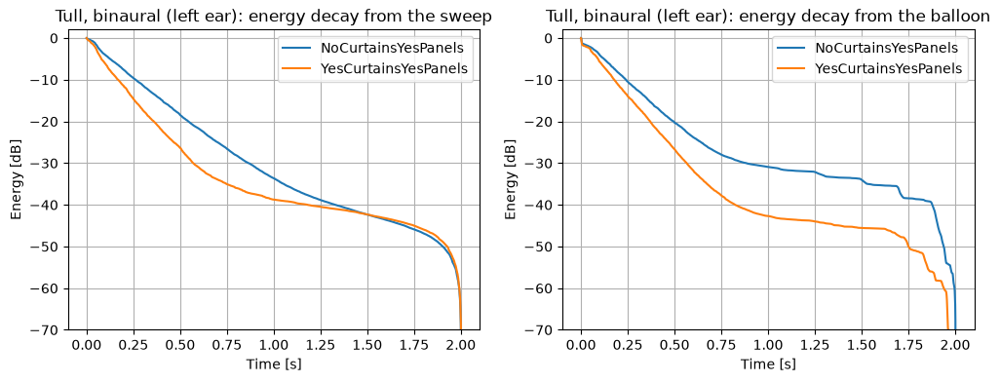

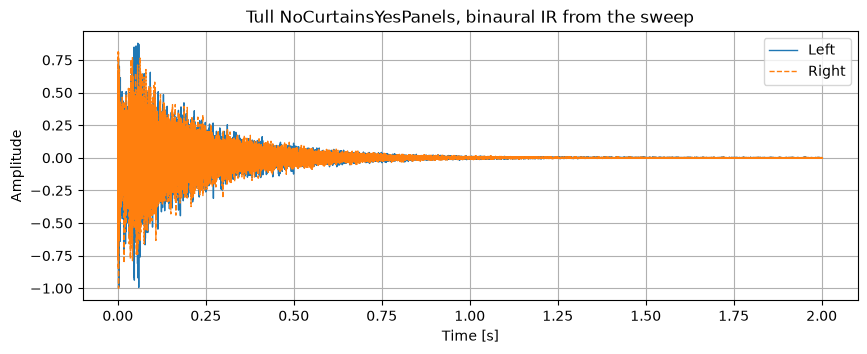

"Drums in Tull, NoCurtainsYesPanels, binaural IR from the sweep",Your browser does not support the audio element.


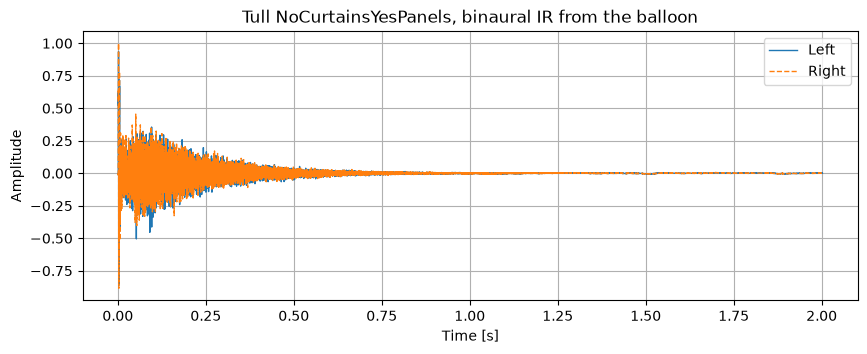

"Drums in Tull, NoCurtainsYesPanels, binaural IR from the balloon",Your browser does not support the audio element.


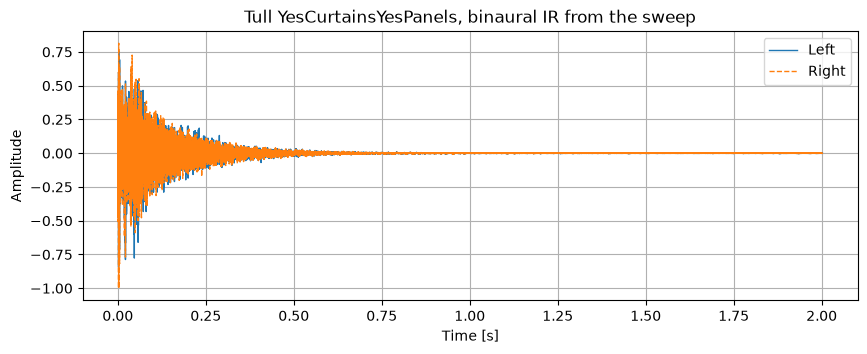

"Drums in Tull, YesCurtainsYesPanels, binaural IR from the sweep",Your browser does not support the audio element.


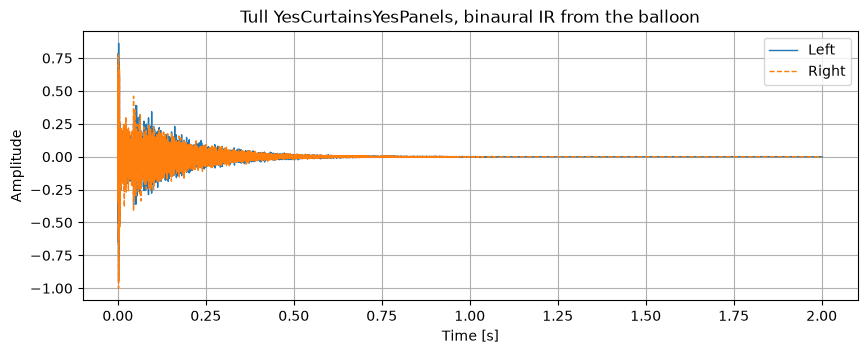

"Drums in Tull, YesCurtainsYesPanels, binaural IR from the balloon",Your browser does not support the audio element.


In [13]:
sr, s = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')

tullDir = "TullMeasurements_14102026"
conditions = {"NoCurtainsYesPanels": "no-curtains-yes-panels", "YesCurtainsYesPanels": "yes-curtains-yes-panels"}


def logSweep(fs, T=4.0, f0=20.0, f1=20000.0):
    L = T / np.log(f1 / f0)
    t = np.arange(int(T * fs)) / fs
    return np.sin(2 * np.pi * f0 * L * (np.exp(t / L) - 1))


irs = {}
for cond, tag in conditions.items():
    fs, y = wavreadFloat(f"{tullDir}/{cond}/sweep2_{tag}_binaural.wav")
    irs[(cond, "sweep")] = cropIR(deconvolve(logSweep(fs), y, fs), fs)
    fs, b = wavreadFloat(f"{tullDir}/{cond}/balloon-center_{tag}_binaural.wav")
    irs[(cond, "balloon")] = cropIR(b, fs)

for (cond, kind), h in irs.items():
    print(f"{cond:22s} {kind:8s} RT60 L/R: {estimateRT60(h[:, 0], fs):.2f} / {estimateRT60(h[:, 1], fs):.2f} s")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (cond, kind), h in irs.items():
    t = np.arange(len(h)) / fs
    ax[0 if kind == "sweep" else 1].plot(t, energyDecay(h[:, 0]), label=cond)
for a, kind in zip(ax, ["sweep", "balloon"]):
    a.set_title(f"Tull, binaural (left ear): energy decay from the {kind}")
    a.set_xlabel("Time [s]")
    a.set_ylabel("Energy [dB]")
    a.set_ylim(-70, 2)
    a.grid(True)
    a.legend()
plt.show()

for (cond, kind), h in irs.items():
    plotIR(h, fs, f"Tull {cond}, binaural IR from the {kind}", style="line")
    sound(convolveIR(s, h), sr, f"Drums in Tull, {cond}, binaural IR from the {kind}")

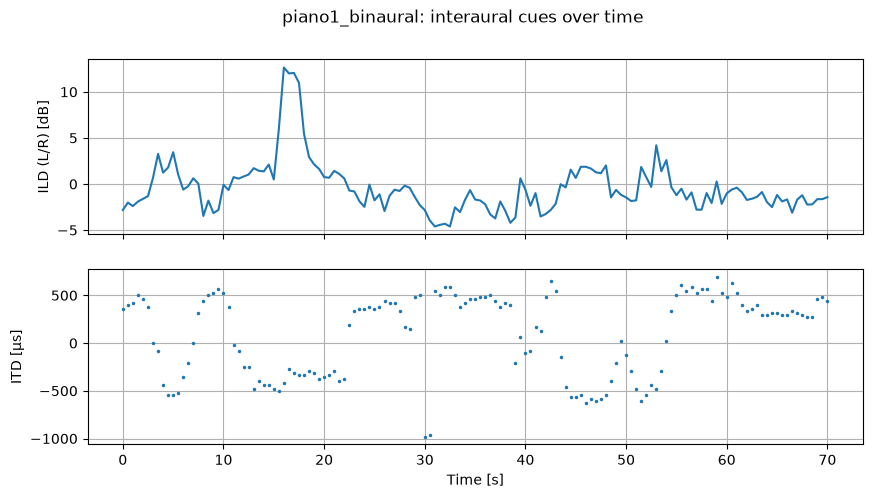

"piano1_binaural, first 30 s",Your browser does not support the audio element.


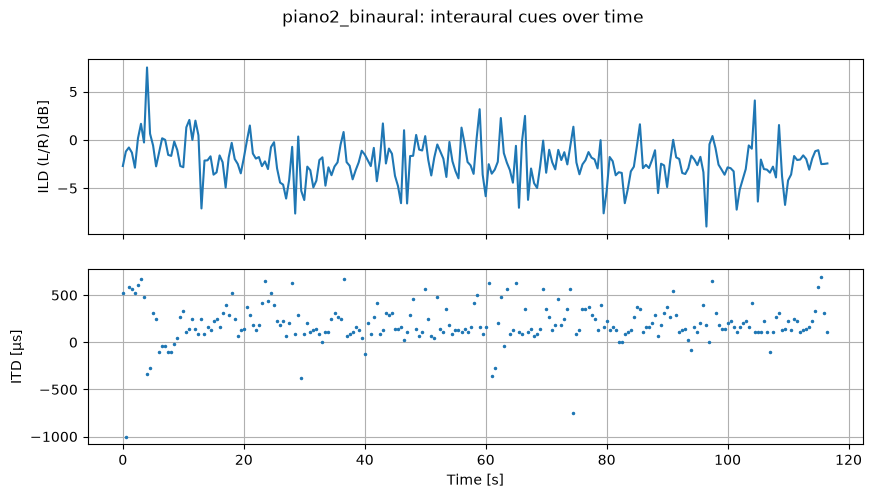

"piano2_binaural, first 30 s",Your browser does not support the audio element.


In [14]:
#binaurale klavieraufnahmen: klingt es, als ob man sich bewegt?
from scipy.signal import correlate, butter, sosfilt, resample_poly

def interaural_cues(x, sr, frame=0.5):
    #ild u. itd pro frame, itd per kreuzkorrelation bei 200-1500 hz
    N = int(frame * sr)
    xb = sosfilt(butter(4, [200, 1500], "bandpass", fs=sr, output="sos"), x, axis=0)
    max_lag = int(0.001 * sr)
    ild, itd = [], []
    for k in range(len(x) // N):
        l, r = x[k*N:(k+1)*N, 0], x[k*N:(k+1)*N, 1]
        ild.append(10 * np.log10((np.sum(l**2) + 1e-12) / (np.sum(r**2) + 1e-12)))
        cc = correlate(xb[k*N:(k+1)*N, 0], xb[k*N:(k+1)*N, 1], "full")[N - 1 - max_lag:N + max_lag]
        itd.append((np.argmax(cc) - max_lag) / sr * 1e6) #itd > 0: l. ohr später, klavier rechts
    return np.arange(len(ild)) * frame, np.array(ild), np.array(itd)


for name in ["piano1_binaural", "piano2_binaural"]:
    sr_p, x = wavfile.read(f"TullMeasurements_14102026/Piano/{name}.wav")
    x = x.astype("float64")
    t, ild, itd = interaural_cues(x, sr_p)

    fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 5))
    fig.suptitle(f"{name}: interaural cues over time")
    ax[0].plot(t, ild)
    ax[0].set_ylabel("ILD (L/R) [dB]")
    ax[0].grid(True)
    ax[1].plot(t, itd, ".", markersize=3)
    ax[1].set_ylabel("ITD [µs]")
    ax[1].set_xlabel("Time [s]")
    ax[1].grid(True)
    plt.show()
    #die ersten 30 s mit 24 khz, hält das notebook klein
    sound(resample_poly(x[:30 * sr_p], 1, 2, axis=0).T, sr_p // 2, f"{name}, first 30 s")
#piano1: itd schwankt zw. ca. +500 u. -550 µs, das klavier wechselt alle 5-15 s die seite -> der kopf bewegt sich
#piano2: itd bleibt nach den ersten 10 s bei ca. +150-250 µs, ild ca. -2 db -> statisch, klavier etwas rechts

## Part 5. 

Now let's move to 3D sounds.  For this lab we will focus on models that work with headphones. We will make use of simple filters and HRTFs to create static and moving sources. Use the this sound [https://www.dropbox.com/scl/fi/bm4l8o7rt1uhrxosym5si/crumble.wav?rlkey=jz6b1gd222nhqmtkj6ffiyijm&st=qtbzfvvm&dl=1 ] for all the sound examples.

### Part i: Static sources using ITD/ILD cues

Assume the following source locations: 

- Straight ahead

- 45 degrees to the left

- 80 degrees to the right

- 160 degrees to the left

For each location find the source’s delay between the two ears (assume a source distance of 2 meters), and design two filters that will simulate that ITD and ILD features (feel free to round the IDT delays to an integer sample size). Assume that when sounds come from the side of the head the attenuation at the contralateral ear is by a factor of 0.7. From sounds coming medial plane (between the ears) there will be no attenuation due to the head. For positions moving from the medial plane towards the sides you can interpolate between no attenuation and a factor of 0.7. Design and plot the filters that correspond to the locations shown above and use them to spatialize the test sound.  Try it with other sounds too if you like.

Listen to the result through headphones and verify that it sounds somewhat localized (it won’t sound perfect, but it should be believable).

Azimuth 0°: ITD = +0 µs (0 samples), far ear gain 1.00


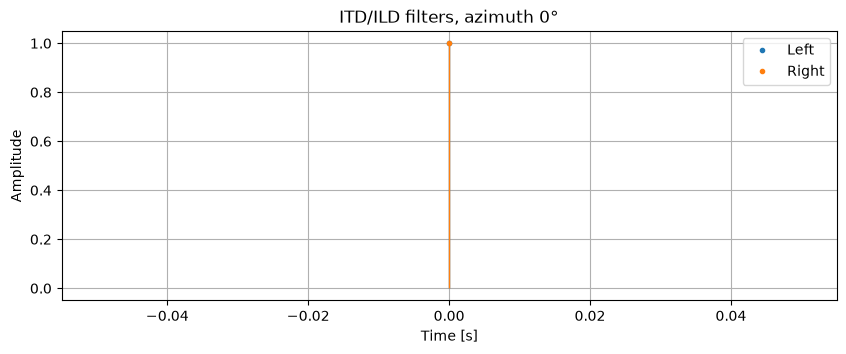

"ITD/ILD, azimuth 0°",Your browser does not support the audio element.


Azimuth 45°: ITD = +383 µs (17 samples), far ear gain 0.79


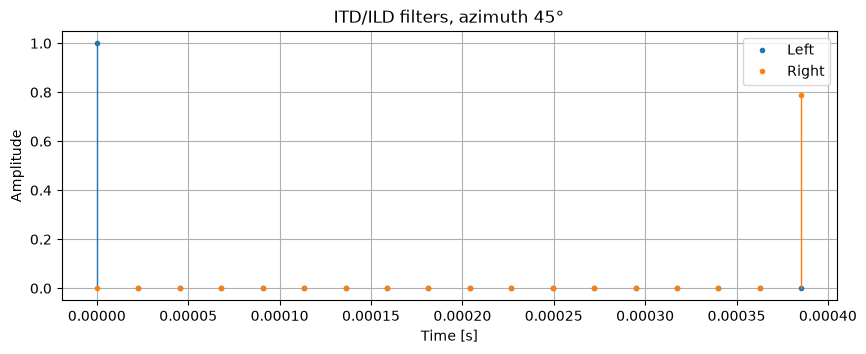

"ITD/ILD, azimuth 45°",Your browser does not support the audio element.


Azimuth -80°: ITD = -613 µs (27 samples), far ear gain 0.70


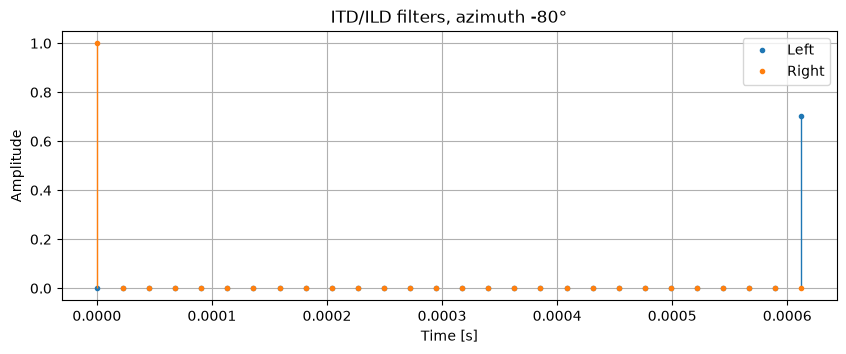

"ITD/ILD, azimuth -80°",Your browser does not support the audio element.


Azimuth 160°: ITD = +177 µs (8 samples), far ear gain 0.90


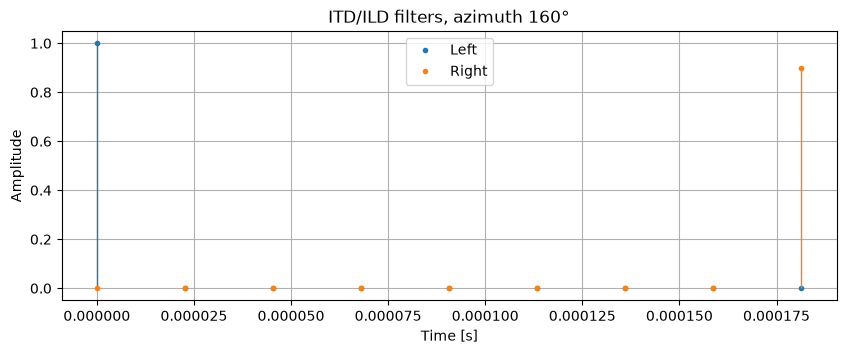

"ITD/ILD, azimuth 160°",Your browser does not support the audio element.


In [15]:
sr, s = wavreadurl('https://www.dropbox.com/scl/fi/bm4l8o7rt1uhrxosym5si/crumble.wav?rlkey=jz6b1gd222nhqmtkj6ffiyijm&st=qtbzfvvm&dl=1')


def earPaths(azimuth, r=2.0, a=0.0875):
    #kugelkopf: gerade linie zum sichtbaren ohr, tangente + bogen um den kopf zum verdeckten
    theta = np.deg2rad(azimuth)
    psi = np.arccos(a / r)
    def path(sep):
        return np.sqrt(r**2 + a**2 - 2 * r * a * np.cos(sep)) if sep <= psi else np.sqrt(r**2 - a**2) + a * (sep - psi)
    return path(np.arccos(np.sin(theta))), path(np.arccos(-np.sin(theta)))


def itdIldFilters(azimuth, fs, r=2.0, a=0.0875, c=343.0, gSide=0.7):
    #azimut: 0° vorne, positiv nach links
    dL, dR = earPaths(azimuth, r, a)
    n = int(round(abs(dR - dL) / c * fs))
    gFar = 1 - (1 - gSide) * abs(np.sin(np.deg2rad(azimuth)))
    hNear, hFar = np.zeros(n + 1), np.zeros(n + 1)
    hNear[0], hFar[n] = 1.0, gFar
    return (hNear, hFar) if dL <= dR else (hFar, hNear)


for azimuth in [0, 45, -80, 160]:
    hL, hR = itdIldFilters(azimuth, sr)
    dL, dR = earPaths(azimuth)
    print(f"Azimuth {azimuth}°: ITD = {(dR - dL) / 343 * 1e6:+.0f} µs ({len(hL) - 1} samples), far ear gain {min(hL.max(), hR.max()):.2f}")
    plotIR(np.column_stack((hL, hR)), sr, f"ITD/ILD filters, azimuth {azimuth}°")
    sound(np.array([np.convolve(s, hL), np.convolve(s, hR)]), sr, f"ITD/ILD, azimuth {azimuth}°")

#itd 383 µs bei 45°, 613 µs bei 80°, 177 µs bei 160°; vorne u. hinten geben dieselbe itd, also kein vorne/hinten-hinweis

### Part ii: Static sources using HRTFs

Download the HTTF archive from [https://www.dropbox.com/scl/fi/rk9vy4axcazrhxhkudrxy/compact.zip?rlkey=2mvuy2sa3zxcbzjtsiaf677gp&dl=1 ]. Below you will also find code for the function load_hrtf which returns the left and right HRTF filters given as input a source’s azimuth and elevation. These filters will be much better than the ITD/ILD filters for localizing sounds.

Apply the HRTFs on the given test sound and create 3D sounds that correspond to the locations given above. You will need to convolve with the left and right HRTF of the desired position and generate two sounds, one for each channel. Verify that they sound correct using headphones; are they better than before? What differences do you observe? When you use these make sure that the sample rates of the HRTFs and the sound you convolve them with match.  The HRTFs are sampled at 44.1kHz. As usual make sure you make some plots to make sure that filters look ok.

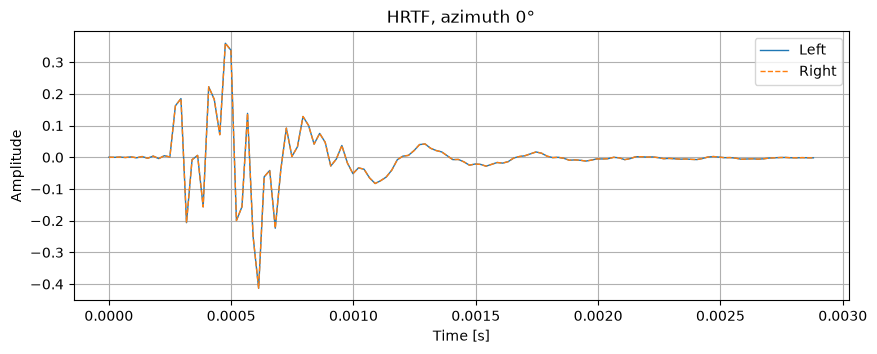

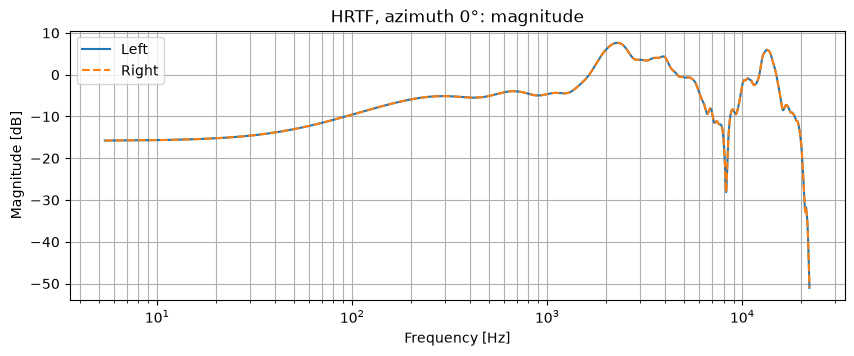

Azimuth 0°: HRTF ITD +0 samples, ILD +0.0 dB | model ITD +0 samples, ILD +0.0 dB


"HRTF, azimuth 0°",Your browser does not support the audio element.


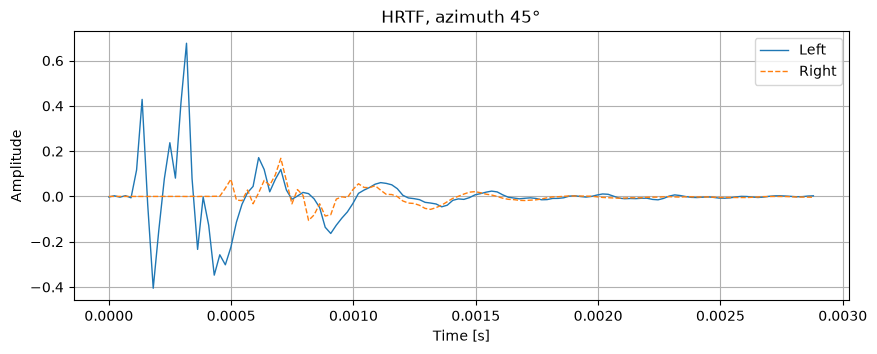

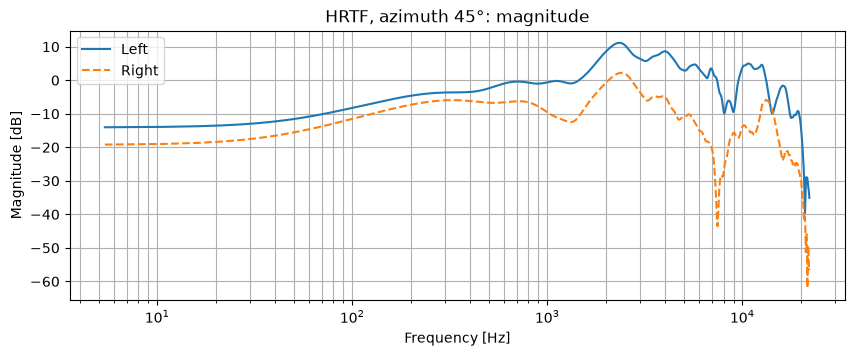

Azimuth 45°: HRTF ITD -17 samples, ILD +11.3 dB | model ITD -17 samples, ILD +2.1 dB


"HRTF, azimuth 45°",Your browser does not support the audio element.


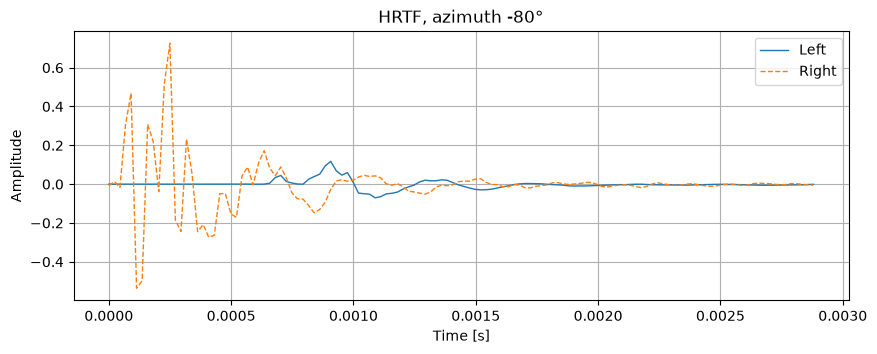

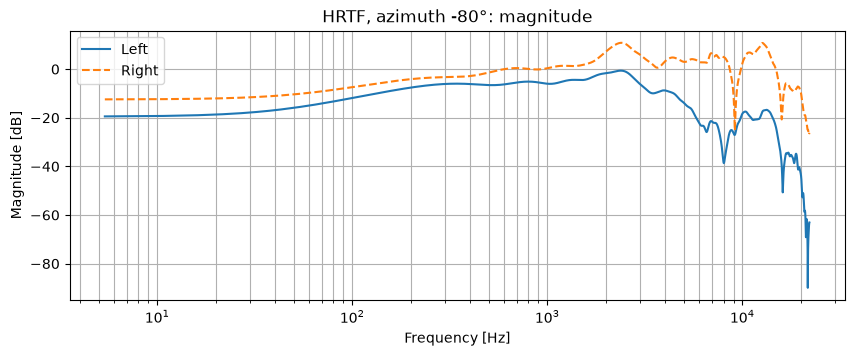

Azimuth -80°: HRTF ITD +29 samples, ILD -15.2 dB | model ITD +27 samples, ILD -3.0 dB


"HRTF, azimuth -80°",Your browser does not support the audio element.


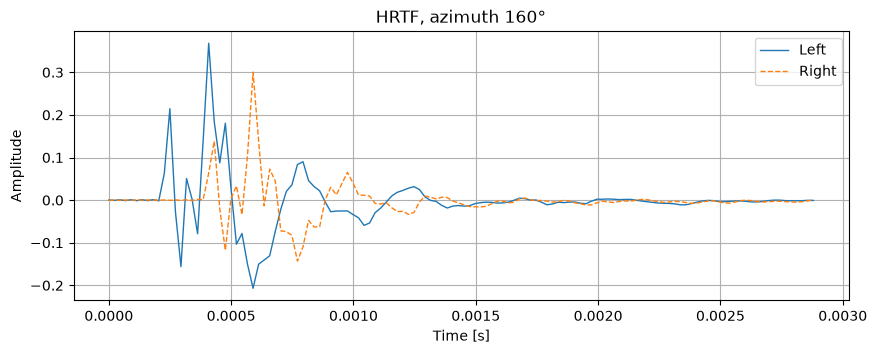

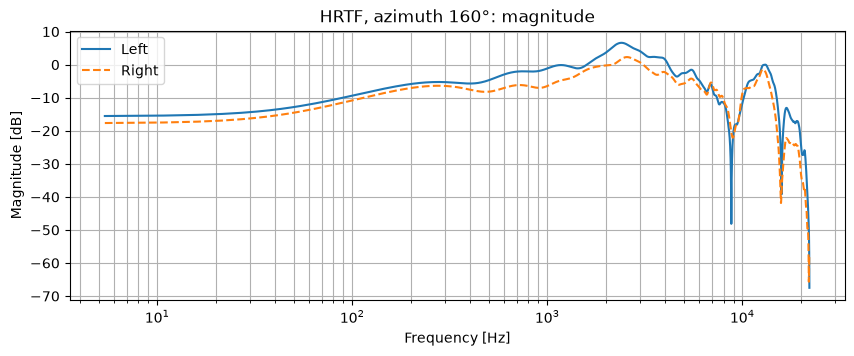

Azimuth 160°: HRTF ITD -8 samples, ILD +3.1 dB | model ITD -8 samples, ILD +0.9 dB


"HRTF, azimuth 160°",Your browser does not support the audio element.


In [16]:
def load_hrtf( ad, ed):
    # Return the HRTFs for a given azimuth and elevation
    #  function h,a,e = load_hrtf( ad, ed)
    #
    # Inputs:
    #   ad  is the azimuth to use in degrees (0 is front)
    #   ed  is the elevation to use in degrees (0 is level with ears)
    #
    # Output:
    #   l,r two 128pt arrays, first is left ear HRTF, second is right ear HRTF
    from numpy import remainder, fromfile

    # Path where the HRTFs are
    p = './compact/'

    # Get nearest available elevation
    e = max( -40, min( 90, 10*(ed//10)))

    # Get nearest available azimuth
    ad = remainder( ad, 360)
    if ad > 180:
        ad = ad-360
    if ad < 0:
        a = abs( ad)
        fl = 1
    else:
        a = ad
        fl = 0
    a = max( 0, min( 180, 5*(a//5)))

    # Load appropriate response
    h = fromfile( '%s/elev%d/H%de%.3da.dat' % (p, e, e, a), dtype='>i2').astype( 'double')/32768
    if fl:
        return h[1::2],h[::2]
    else:
        return h[::2],h[1::2]



sr, s = wavreadurl('https://www.dropbox.com/scl/fi/bm4l8o7rt1uhrxosym5si/crumble.wav?rlkey=jz6b1gd222nhqmtkj6ffiyijm&st=qtbzfvvm&dl=1')

for azimuth in [0, 45, -80, 160]:
    hL, hR = load_hrtf(-azimuth, 0) #load_hrtf zählt nach rechts positiv
    plotIR(np.column_stack((hL, hR)), sr, f"HRTF, azimuth {azimuth}°", style="line")
    f, HL = filterSpectrum(hL, 1, sr, 2**12)
    _, HR = filterSpectrum(hR, 1, sr, 2**12)
    plt.figure(figsize=(10, 3.5))
    plt.semilogx(f[1:], 20 * np.log10(np.abs(HL[1:]) + 1e-12), label="Left")
    plt.semilogx(f[1:], 20 * np.log10(np.abs(HR[1:]) + 1e-12), "--", label="Right")
    plt.title(f"HRTF, azimuth {azimuth}°: magnitude")
    plt.xlabel("Frequency [Hz]")
    plt.ylabel("Magnitude [dB]")
    plt.legend()
    plt.grid(True, which="both")
    plt.show()
    itd = np.argmax(signal.correlate(hL, hR, "full")) - (len(hR) - 1) #> 0: l. ohr später
    ild = 10 * np.log10(np.sum(hL**2) / np.sum(hR**2))
    mL, mR = itdIldFilters(azimuth, sr)
    print(f"Azimuth {azimuth}°: HRTF ITD {itd:+d} samples, ILD {ild:+.1f} dB | model ITD {np.argmax(mL) - np.argmax(mR):+d} samples, ILD {20 * np.log10(mL.max() / mR.max()):+.1f} dB")
    sound(np.array([np.convolve(s, hL), np.convolve(s, hR)]), sr, f"HRTF, azimuth {azimuth}°")

#die itd vom kugelkopf passt fast genau zur hrtf (17/27/8 vs. 17/29/8 samples)
#aber die ild der hrtf ist viel größer u. freq.-abhängig (+11.3 vs. +2.1 db bei 45°, -15.2 vs. -3.0 db bei -80°)

### Part iii: Dynamic sources with HRTFs

In this part you will need to make a moving sound source. In order to do so we will make use of a fast convolution routine based on your STFT code from lab 1 (ha, you thought you were done with that!). In order to perform fast convolution we can perform an STFT of the sound to use, multiply each time frame of this transform with the DFT of the filter that we want  to impose and then use overlap add to transform back to the time domain.

Start by taking each sound from above, and apply your STFT on it. Make sure that the size of the transform is the same as the HRTF’s filter length. The hop size should be the same as the DFT size and you will need to zero pad each frame by as much as the DFT size in order to facilitate the tail of the convolution. Do not use an analysis/synthesis window.

Once you compute this STFT, go through its every time frame and element-wise multiply it with the desired HRTF filter to generate the STFT of the left and right sounds. Figure out which HRTF angle to multiply each frame with so that by the end of the sound you will have made it go around your head.

Once you perform these operations you will have generated two STFT matrices, one for the left channel and one for the right. Use your inverse STFT routine and play the stereo sound through your headphones. You should hear a convincing rendering of the original sounds circling around your head.

Render the sounds so that we can listen to them too.

Crunch circling the head,Your browser does not support the audio element.


Drums circling the head twice,Your browser does not support the audio element.


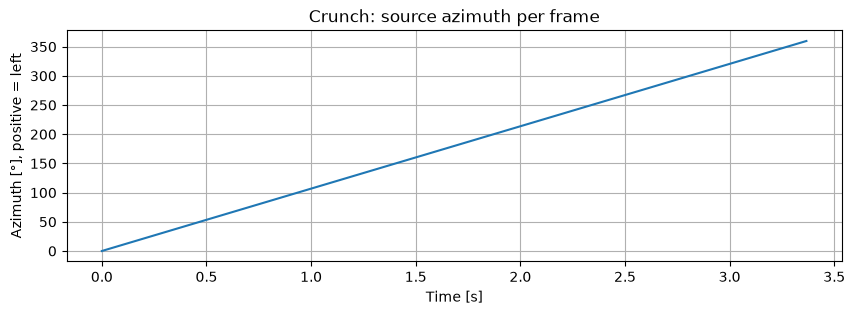

In [17]:
def stftAnal(x, N, H, pad):
    nFrames = int(np.ceil(len(x) / H))
    x = np.append(x, np.zeros(nFrames * H + N - len(x)))
    X = np.empty((nFrames, (N + pad) // 2 + 1), dtype=complex)
    for l in range(nFrames):
        X[l] = np.fft.rfft(x[l * H:l * H + N], N + pad) #kein fenster, mit nullen aufgefüllt
    return X


def stftSynth(Y, N, H, pad):
    M = N + pad
    y = np.zeros(Y.shape[0] * H + M)
    for l in range(Y.shape[0]):
        y[l * H:l * H + M] += np.fft.irfft(Y[l], M) #overlap-add
    return y


def hrtfCircle(x, nTurns=1, N=128):
    X = stftAnal(x, N, N, N) #dft-größe = hrtf-länge, hop = dft-größe, padding = dft-größe
    azimuths = 360 * nTurns * np.arange(X.shape[0]) / X.shape[0]
    spectra = {}
    YL, YR = np.empty_like(X), np.empty_like(X)
    for l, az in enumerate(azimuths):
        k = int(5 * round(az / 5)) % 360
        if k not in spectra:
            hL, hR = load_hrtf(-k, 0) #positiv = links, die quelle läuft vorne -> links -> hinten -> rechts
            spectra[k] = np.fft.rfft(hL, 2 * N), np.fft.rfft(hR, 2 * N)
        YL[l] = X[l] * spectra[k][0]
        YR[l] = X[l] * spectra[k][1]
    n = len(x) + N
    return np.array([stftSynth(YL, N, N, N)[:n], stftSynth(YR, N, N, N)[:n]]), azimuths


srC, crunch = wavreadurl('https://www.dropbox.com/scl/fi/bm4l8o7rt1uhrxosym5si/crumble.wav?rlkey=jz6b1gd222nhqmtkj6ffiyijm&st=qtbzfvvm&dl=1')
srD, drums = wavreadurl('https://www.dropbox.com/scl/fi/c7ecz4ra2v0j9m45zay1v/loop.wav?rlkey=spp3fzx44mfz4x9ke4pbbv7sl&dl=1')
drums = signal.resample_poly(drums, 147, 160) #48 khz -> 44.1 khz wie die hrtfs

yC, az = hrtfCircle(crunch)
sound(yC, srC, "Crunch circling the head")
yD, _ = hrtfCircle(drums, nTurns=2)
sound(yD, 44100, "Drums circling the head twice")

plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(az)) * 128 / srC, az)
plt.title("Crunch: source azimuth per frame")
plt.xlabel("Time [s]")
plt.ylabel("Azimuth [°], positive = left")
plt.grid(True)
plt.show()

#der crunch macht eine runde, die drums zwei
#alle 128 samples (2.9 ms) eine neue hrtf, daher ist die bewegung flüssig